# Adversarial Search: Playing Dots and Boxes


## Instructions

Total Points: Undegraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play the game Dots and Boxes:

> "Dots and Boxes is a pencil-and-paper game for two players. The game starts with an empty grid of dots. Usually two players take turns adding a single horizontal or vertical line between two unjoined adjacent dots. A player who completes the fourth side of a 1x1 box earns one point and takes another turn. A point is typically recorded by placing a mark that identifies the player in the box, such as an initial. The game ends when no more lines can be placed. The winner is the player with the most points. The board may be of any size grid." (see [Dots and Boxes on Wikipedia](https://en.wikipedia.org/wiki/Dots_and_Boxes))

You can play Dots and Boxes [here](https://www.math.ucla.edu/~tom/Games/dots&boxes.html).

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

In [1]:
# Your code/ answer goes here.
# Định nghĩa bài toán tìm kiếm (kích thước bàn = số ĐIỂM: rows x cols; số ô vuông = (rows-1) x (cols-1))
#
# - Trạng thái đầu : bàn cờ trống: lines = {}, boxes = {}; người đi trước là +1.
# - Hành động      : actions(s) = mọi đoạn thẳng ('h'|'v', row, col) chưa được vẽ.
# - Mô hình chuyển : result(s, a, player) = vẽ đoạn a; nếu hoàn thành k >= 1 ô thì ghi
#                    boxes[(r, c)] = player và NGƯỜI ĐÓ ĐI TIẾP; ngược lại đến lượt đối thủ.
# - Kiểm tra kết thúc: terminal(s) = True khi tất cả các đoạn thẳng đã được vẽ (không còn hành động).
# - Hàm lợi ích    : utility(s, player) = (số ô của player) - (số ô của đối thủ).
#                    > 0 thắng, = 0 hòa, < 0 thua.
print("Xem định nghĩa ở trên; cài đặt cụ thể ở Task 2.")

Xem định nghĩa ở trên; cài đặt cụ thể ở Task 2.


How big is the state space? Give an estimate and explain it.

In [2]:
# Your code/ answer goes here.
def num_lines(rows, cols):
    """Số đoạn thẳng của bàn rows x cols điểm."""
    return rows * (cols - 1) + (rows - 1) * cols

print(f"{'Bàn (điểm)':<12}{'Ô vuông':<10}{'Số đoạn L':<11}{'Trạng thái <= 2^L':>20}{'Số ván tối đa L!':>25}")
for rows, cols in [(3, 3), (3, 4), (4, 4), (4, 5), (5, 5)]:
    L = num_lines(rows, cols)
    import math
    print(f"{rows}x{cols:<9}{(rows-1)}x{(cols-1):<8}{L:<11}{2**L:>20,}{math.factorial(L):>25.3e}")

# Mỗi đoạn thẳng chỉ có 2 trạng thái (đã vẽ / chưa vẽ) -> không gian trạng thái <= 2^L
# (ai sở hữu ô nào được suy ra từ lịch sử nên số trạng thái "thật" lớn hơn một chút nếu tính cả
#  người chơi đang đến lượt, nhưng cùng bậc 2^L).

Bàn (điểm)  Ô vuông   Số đoạn L     Trạng thái <= 2^L         Số ván tối đa L!
3x3        2x2       12                        4,096                4.790e+08
3x4        2x3       17                      131,072                3.557e+14
4x4        3x3       24                   16,777,216                6.204e+23
4x5        3x4       31                2,147,483,648                8.223e+33
5x5        4x4       40            1,099,511,627,776                8.159e+47


How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [3]:
# Your code/ answer goes here.
# Cây trò chơi mà minimax duyệt: mỗi ván là một hoán vị của L đoạn thẳng
# => tối đa L! lá (không tính nhánh cắt tỉa). Thực tế ít hơn vì ván có thể sinh ra cùng một trạng thái
# theo nhiều thứ tự khác nhau, nhưng minimax thuần vẫn duyệt lặp lại các trạng thái đó.
# Ví dụ: bàn 3x3 điểm (2x2 ô) có L = 12 -> 12! ~ 4.8e8 ván; bàn 4x4 điểm (3x3 ô) có L = 24 -> 24! ~ 6.2e23 ván.
import math
for rows, cols in [(3, 3), (3, 4), (4, 4), (5, 5)]:
    L = num_lines(rows, cols)
    print(f"{rows}x{cols} điểm: L = {L}, L! = {math.factorial(L):.3e}")

3x3 điểm: L = 12, L! = 4.790e+08
3x4 điểm: L = 17, L! = 3.557e+14
4x4 điểm: L = 24, L! = 6.204e+23
5x5 điểm: L = 40, L! = 8.159e+47


## Task 2: Game Environment and Random Agent [30 point]

You need to think about a data structure to represent the board meaning he placed lines and who finished what box. There are many options. Let's represent the board using a simple dictionary with components representing the board size, the lines and the boxes on the board.

**Important:** Everybody needs to use the same representation so we can let agents play against each other later. 

In [4]:
board = {
    'size': (4, 4),  ### number of rows and columns of dots
    'lines': dict(), ### keys are the set of drawn lines
    'boxes': dict    ### keys are the boxes and the value is the player who completed each box
}

def draw_line(board, orientation, row, col):
    """
    Place a line on an exiting board.
       
    Parameters
    ----------
    board: dict
        the board
    orientation: str
        either 'h' or 'v' for horizontal or vertical
    row, col: int
        index of the starting dot for the line (starting with 0)
    
    """
    
    if orientation not in ['h', 'v']:
        return False
        
    if row < 0 or col < 0:
        return False
        
    if row >= board['size'][0] + (orientation == 'v') or col >= board['size'][1] + (orientation == 'h'):
        return False
        
    if (orientation, row, col) in board['lines']:
        return False
            
    board["lines"][(orientation, row, col)] = True
    return True
    

print(draw_line(board, "h", 1, 1))
print(draw_line(board, "v", 1, 1))

# this should not work
print(draw_line(board, "h", 1, 1))

board

True
True
False


{'size': (4, 4),
 'lines': {('h', 1, 1): True, ('v', 1, 1): True},
 'boxes': dict}

In [5]:
import random, time, math
from functools import lru_cache

def make_board(rows=4, cols=4):
    """Tạo bàn trống. rows, cols = số ĐIỂM (dots). Số ô vuông = (rows-1) x (cols-1)."""
    return {'size': (rows, cols), 'lines': dict(), 'boxes': dict()}

@lru_cache(maxsize=None)
def all_lines(size):
    """Danh sách mọi đoạn thẳng hợp lệ của bàn có kích thước size (rows, cols điểm)."""
    R, C = size
    return tuple([('h', r, c) for r in range(R) for c in range(C - 1)] +
                 [('v', r, c) for r in range(R - 1) for c in range(C)])

def draw_line(board, orientation, row, col):
    """Vẽ một đoạn thẳng lên bàn (đã sửa điều kiện biên cho đúng với size = số điểm).
       'h': (row, col) -> (row, col+1)   với 0 <= row < R,   0 <= col < C-1
       'v': (row, col) -> (row+1, col)   với 0 <= row < R-1, 0 <= col < C
    """
    if orientation not in ['h', 'v']:
        return False
    if (orientation, row, col) not in all_lines(board['size']):
        return False
    if (orientation, row, col) in board['lines']:
        return False
    board['lines'][(orientation, row, col)] = True
    return True

board = make_board(4, 4)
print(draw_line(board, "h", 1, 1))
print(draw_line(board, "v", 1, 1))
# cái này phải trả về False (đã vẽ rồi)
print(draw_line(board, "h", 1, 1))
# đoạn nằm ngoài bàn -> False
print(draw_line(board, "h", 1, 3))
board

True
True
False
False


{'size': (4, 4), 'lines': {('h', 1, 1): True, ('v', 1, 1): True}, 'boxes': {}}

Write code to display the board. **Bonus point: Post your visualization code with an example output to the discussion board. The best visualization will earn you bonus participation points in this class.**

+   +   +   +
             
+   +---+   +
    |        
+   +   +   +
             
+   +   +   +


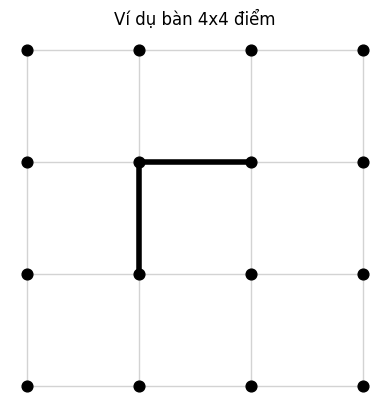

In [6]:
# Your code/ answer goes here.
import matplotlib.pyplot as plt

def show_board(board):
    """Hiển thị bàn dạng văn bản. X = +1 (đỏ), O = -1 (vàng)."""
    R, C = board['size']
    sym = {1: 'X', -1: 'O'}
    for r in range(R):
        row = ''
        for c in range(C - 1):
            row += '+' + ('---' if ('h', r, c) in board['lines'] else '   ')
        print(row + '+')
        if r < R - 1:
            row = ''
            for c in range(C):
                row += '|' if ('v', r, c) in board['lines'] else ' '
                if c < C - 1:
                    row += ' ' + sym.get(board['boxes'].get((r, c), 0), ' ') + ' '
            print(row)

def plot_board(board, title=None):
    """Vẽ bàn bằng matplotlib: ô của +1 tô đỏ, ô của -1 tô vàng."""
    R, C = board['size']
    fig, ax = plt.subplots(figsize=(1.2 * C, 1.2 * R))
    color = {1: 'tomato', -1: 'gold'}
    for (r, c), p in board['boxes'].items():
        ax.add_patch(plt.Rectangle((c, -r - 1), 1, 1, color=color[p], alpha=0.6))
    for r in range(R):
        for c in range(C - 1):
            ax.plot([c, c + 1], [-r, -r], 'k-' if ('h', r, c) in board['lines'] else 'lightgray',
                    lw=4 if ('h', r, c) in board['lines'] else 1, solid_capstyle='round')
    for r in range(R - 1):
        for c in range(C):
            ax.plot([c, c], [-r, -r - 1], 'k-' if ('v', r, c) in board['lines'] else 'lightgray',
                    lw=4 if ('v', r, c) in board['lines'] else 1, solid_capstyle='round')
    ax.scatter([c for r in range(R) for c in range(C)], [-r for r in range(R) for c in range(C)],
               s=60, c='black', zorder=5)
    ax.set_aspect('equal'); ax.axis('off')
    if title: ax.set_title(title)
    plt.show()

show_board(board)
plot_board(board, "Ví dụ bàn 4x4 điểm")

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

__Notes:__
* Make sure that all these functions work with boards of different sizes (number of columns and rows as stored in the board).
* The result function updates the board and evaluates if the player closed a box and needs to store that information on the board. Add elements of the form `(row,col): player` to the board dictionary. `row` and `col` are the coordinates for the box and `player` is +1 or -1 representing the player. For example `(0,0): -1` means that the top-left box belongs to the other player. 
* _Important:_ Remember that a player goes again after she completes a box!

In [7]:
# Your code/ answer goes here.
def box_sides(r, c):
    """4 cạnh của ô vuông (r, c)."""
    return [('h', r, c), ('h', r + 1, c), ('v', r, c), ('v', r, c + 1)]

def adjacent_boxes(size, line):
    """Các ô vuông (hợp lệ) chứa đoạn thẳng line."""
    R, C = size
    o, r, c = line
    cand = [(r - 1, c), (r, c)] if o == 'h' else [(r, c - 1), (r, c)]
    return [(br, bc) for br, bc in cand if 0 <= br < R - 1 and 0 <= bc < C - 1]

def sides_drawn(board, r, c):
    """Số cạnh đã vẽ của ô (r, c)."""
    return sum(1 for s in box_sides(r, c) if s in board['lines'])

def actions(board):
    """actions(s): mọi đoạn thẳng chưa vẽ."""
    return [l for l in all_lines(board['size']) if l not in board['lines']]

def terminal(board):
    """terminal(s): True khi không còn đoạn thẳng nào để vẽ."""
    return len(board['lines']) == len(all_lines(board['size']))

def result(board, action, player):
    """result(s, a): vẽ đoạn `action` cho `player`. Trả về (bàn mới, người đi tiếp).
       Nếu hoàn thành >= 1 ô: ghi boxes[(r, c)] = player và player được đi tiếp."""
    new = {'size': board['size'], 'lines': dict(board['lines']), 'boxes': dict(board['boxes'])}
    o, r, c = action
    if not draw_line(new, o, r, c):
        raise ValueError(f"Nước đi không hợp lệ: {action}")
    done = 0
    for (br, bc) in adjacent_boxes(new['size'], action):
        if (br, bc) not in new['boxes'] and sides_drawn(new, br, bc) == 4:
            new['boxes'][(br, bc)] = player
            done += 1
    return new, (player if done else -player)

def utility(board, player=1):
    """utility(s): (số ô của player) - (số ô của đối thủ). >0 thắng, 0 hòa, <0 thua."""
    return player * sum(board['boxes'].values())

# Kiểm tra nhanh trên bàn 3x3 điểm (2x2 ô)
b = make_board(3, 3)
p = 1
for a in [('h',0,0), ('h',1,0), ('v',0,0), ('v',0,1)]:   # đoạn cuối hoàn thành ô (0,0)
    b, p2 = result(b, a, p)
    print(a, '-> người đi tiếp:', p2)
    p = p2
show_board(b)
print("terminal:", terminal(b), "| số hành động còn lại:", len(actions(b)), "| utility(+1):", utility(b, 1))

('h', 0, 0) -> người đi tiếp: -1
('h', 1, 0) -> người đi tiếp: 1
('v', 0, 0) -> người đi tiếp: -1
('v', 0, 1) -> người đi tiếp: -1
+---+   +
| O |    
+---+   +
         
+   +   +
terminal: False | số hành động còn lại: 8 | utility(+1): -1


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on by the environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [8]:
# Your code/ answer goes here.
def random_player(board, player=None):
    """Tác tử ngẫu nhiên: chọn đều ngẫu nhiên một đoạn chưa vẽ."""
    return random.choice(actions(board))

def play(agent1, agent2, size=(3, 3), board=None, verbose=False):
    """Cho 2 tác tử chơi 1 ván. agent1 = +1, agent2 = -1. Trả về (utility cho +1, bàn cuối)."""
    board = board if board is not None else make_board(*size)
    agents = {1: agent1, -1: agent2}
    player = 1
    while not terminal(board):
        a = agents[player](board, player)
        board, player = result(board, a, player)
        if verbose:
            show_board(board); print()
    return utility(board, 1), board

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [9]:
# Your code/ answer goes here.
N = 1000
res = {'P1 (+1) thắng': 0, 'P2 (-1) thắng': 0, 'Hòa': 0}
for _ in range(N):
    u, _ = play(random_player, random_player, size=(4, 4))   # 4x4 điểm = 3x3 ô (số ô lẻ -> không thể hòa)
    if u > 0: res['P1 (+1) thắng'] += 1
    elif u < 0: res['P2 (-1) thắng'] += 1
    else: res['Hòa'] += 1
print(res)

res = {'P1 (+1) thắng': 0, 'P2 (-1) thắng': 0, 'Hòa': 0}
for _ in range(N):
    u, _ = play(random_player, random_player, size=(3, 3))   # 3x3 điểm = 2x2 ô (có thể hòa 2-2)
    if u > 0: res['P1 (+1) thắng'] += 1
    elif u < 0: res['P2 (-1) thắng'] += 1
    else: res['Hòa'] += 1
print(res)

{'P1 (+1) thắng': 498, 'P2 (-1) thắng': 502, 'Hòa': 0}
{'P1 (+1) thắng': 427, 'P2 (-1) thắng': 433, 'Hòa': 140}


## Task 3: Minimax Search with Alpha-Beta Pruning [30 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for larger board may be too large. You can experiment with smaller boards.
* Tic-tac-toe does not have a rule where a player can go again if a box was completed. You need to adapt the tree search to reflect that rule.

In [10]:
# Your code/ answer goes here.
import time

INF = float('inf')

class SearchTimeout(Exception):
    pass

def _ab(board, to_move, me, alpha, beta, depth, h, order, stats):
    """Alpha-Beta có xử lý LƯỢT ĐI THÊM: người đi tiếp (to_move) do result() quyết định,
       nên một nút có thể là MAX hoặc MIN tùy to_move == me, chứ không đổi luân phiên."""
    stats['nodes'] += 1
    if stats['deadline'] and stats['nodes'] % 2048 == 0 and time.time() > stats['deadline']:
        raise SearchTimeout()
    if terminal(board):
        return utility(board, me)
    if depth == 0:
        return h(board, me, to_move)
    acts = actions(board)
    if order:
        acts = order(board, acts)
    if to_move == me:                      # nút MAX
        v = -INF
        for a in acts:
            nb, nxt = result(board, a, to_move)
            v = max(v, _ab(nb, nxt, me, alpha, beta, depth - 1, h, order, stats))
            alpha = max(alpha, v)
            if v >= beta: break            # cắt beta
        return v
    else:                                  # nút MIN
        v = INF
        for a in acts:
            nb, nxt = result(board, a, to_move)
            v = min(v, _ab(nb, nxt, me, alpha, beta, depth - 1, h, order, stats))
            beta = min(beta, v)
            if v <= alpha: break           # cắt alpha
        return v

def alpha_beta_search(board, player, depth=None, h=None, order=None, time_limit=None):
    """Tìm nước đi tốt nhất cho `player`. depth=None -> tìm kiếm đầy đủ tới nút kết thúc.
       Trả về (action, value, stats)."""
    stats = {'nodes': 0, 'deadline': (time.time() + time_limit) if time_limit else None}
    d = depth if depth is not None else 10**9
    acts = actions(board)
    if order:
        acts = order(board, acts)
    best_a, best_v, alpha = None, -INF, -INF
    for a in acts:
        nb, nxt = result(board, a, player)
        v = _ab(nb, nxt, player, alpha, INF, d - 1, h, order, stats)
        if v > best_v:
            best_v, best_a = v, a
        alpha = max(alpha, best_v)
    return best_a, best_v, stats

def alpha_beta_player(board, player=None):
    """Tác tử Alpha-Beta (tìm kiếm đầy đủ, chỉ dùng cho bàn nhỏ)."""
    return alpha_beta_search(board, player)[0]

Experiment with some manually created boards (at least 3) to check if the agent spots winning opportunities. Discuss the results.

In [11]:
# Your code/ answer goes here.
def make_position(size, lines):
    """Tạo bàn từ danh sách đoạn đã vẽ (người chơi luân phiên +1, -1; ô hoàn thành được ghi đúng chủ)."""
    b = make_board(*size); p = 1
    for l in lines:
        b, p = result(b, l, p)
    return b, p

# Thế cờ 1: có sẵn ô 3 cạnh -> phải ăn ngay (3 cạnh của ô (0,0))
b1, p1 = make_position((3, 3), [('h',0,0), ('v',0,0), ('v',0,1)])
# Thế cờ 2: mọi ô đều đã có 2 cạnh (vòng khép kín) -> bất kỳ nước nào cũng mở đường cho đối thủ ăn
b2, p2 = make_position((3, 3), [('h',0,0), ('h',0,1), ('v',0,0), ('v',0,2), ('h',2,0), ('h',2,1), ('v',1,0), ('v',1,2)])
# Thế cờ 3: 7 đoạn đầu tiên đã vẽ, còn 5 đoạn
b3, p3 = make_position((3, 3), [l for l in all_lines((3, 3))][:7])

for name, (b, p) in {'Thế 1': (b1, p1), 'Thế 2': (b2, p2), 'Thế 3': (b3, p3)}.items():
    print('=====', name, '- đến lượt:', p)
    show_board(b)
    a, v, st = alpha_beta_search(b, p)
    print('-> nước đi:', a, '| giá trị (chênh lệch ô cuối ván):', v, '| số nút:', st['nodes'], '\n')

===== Thế 1 - đến lượt: -1
+---+   +
|   |    
+   +   +
         
+   +   +
-> nước đi: ('h', 1, 0) | giá trị (chênh lệch ô cuối ván): 0 | số nút: 9196 

===== Thế 2 - đến lượt: 1
+---+---+
|       |
+   +   +
|       |
+---+---+
-> nước đi: ('h', 1, 0) | giá trị (chênh lệch ô cuối ván): -4 | số nút: 33 

===== Thế 3 - đến lượt: -1
+---+---+
|        
+---+---+
         
+---+---+
-> nước đi: ('v', 0, 1) | giá trị (chênh lệch ô cuối ván): 0 | số nút: 51 



How long does it take to make a move? Start with a smaller board make the board larger. What is the largest board you can solve?

In [12]:
# Your code/ answer goes here.
import pandas as pd

def time_move(rows, cols, n_drawn=0, time_limit=60, seed=0, **kw):
    """Đo thời gian chọn 1 nước đi trên bàn rows x cols đã vẽ ngẫu nhiên n_drawn đoạn."""
    random.seed(seed)
    b, p = make_board(rows, cols), 1
    for _ in range(n_drawn):
        b, p = result(b, random.choice(actions(b)), p)
    t = time.time()
    try:
        a, v, st = alpha_beta_search(b, p, time_limit=time_limit, **kw)
        return {'bàn (điểm)': f'{rows}x{cols}', 'đoạn đã vẽ': n_drawn, 'còn lại': len(actions(b)),
                'nút': st['nodes'], 'giây': round(time.time() - t, 2), 'kết quả': 'xong'}
    except SearchTimeout:
        return {'bàn (điểm)': f'{rows}x{cols}', 'đoạn đã vẽ': n_drawn, 'còn lại': len(actions(b)),
                'nút': None, 'giây': f'>{time_limit}', 'kết quả': 'quá thời gian'}

# Bàn trống, tăng dần kích thước; mỗi lần cho tối đa 60s.
rows_ = []
for (r, c) in [(2, 3), (3, 3), (3, 4)]:
    rows_.append(time_move(r, c, 0, time_limit=60))
pd.DataFrame(rows_)

,bàn (điểm),đoạn đã vẽ,còn lại,nút,giây,kết quả
0,2x3,0,7,1397.0,0.01,xong
1,3x3,0,12,871815.0,5.49,xong
2,3x4,0,17,NaN,>60,quá thời gian


### Bộ giải nhanh (bitmask + bảng chuyển vị) để tìm bàn lớn nhất giải được

Cài đặt Alpha-Beta dạng negamax trên bitmask, có bảng chuyển vị. Giá trị dương = người đi trước hơn bấy nhiêu ô.

In [13]:
# ===== Bộ giải nhanh (tùy chọn) để trả lời "bàn lớn nhất giải được" =====
# Dùng bitmask + bảng chuyển vị (transposition table) cho Alpha-Beta dạng negamax.
# Nhận xét then chốt: giá trị phần còn lại của ván CHỈ phụ thuộc vào tập đoạn đã vẽ (mask) và người đang đi
# (ô nào đã ăn đã nằm ngoài cuộc chơi), nên một bảng khóa theo mask là đủ.

def make_fast_solver(size, time_limit=None):
    R, C = size
    lines = all_lines(size)
    idx = {l: i for i, l in enumerate(lines)}
    L = len(lines)
    boxes = [(r, c) for r in range(R - 1) for c in range(C - 1)]
    bmask = [sum(1 << idx[s] for s in box_sides(r, c)) for (r, c) in boxes]
    line_boxes = [[bmask[j] for j, bx in enumerate(boxes) if bx in adjacent_boxes(size, l)] for l in lines]
    full = (1 << L) - 1
    tt = {}
    stats = {'nodes': 0, 'deadline': (time.time() + time_limit) if time_limit else None}

    def nega(mask, alpha, beta):
        """Giá trị (số ô thêm - số ô đối thủ thêm) cho người đang đi tại thế `mask`."""
        stats['nodes'] += 1
        if stats['deadline'] and (stats['nodes'] & 4095) == 0 and time.time() > stats['deadline']:
            raise SearchTimeout()
        if mask == full:
            return 0
        lo, hi = tt.get(mask, (-INF, INF))
        if lo >= beta: return lo
        if hi <= alpha: return hi
        alpha0 = alpha
        alpha, beta = max(alpha, lo), min(beta, hi)
        moves = []
        for i in range(L):
            if mask >> i & 1: continue
            nm = mask | (1 << i)
            k = 0; sac = False
            for bm in line_boxes[i]:
                x = nm & bm
                if x == bm: k += 1
                elif bin(x).count('1') == 3: sac = True
            moves.append((0 if k else (2 if sac else 1), i, nm, k))
        moves.sort()
        best = -INF
        for _, i, nm, k in moves:
            v = k + nega(nm, alpha - k, beta - k) if k else -nega(nm, -beta, -alpha)
            if v > best:
                best = v
                if best > alpha: alpha = best
                if alpha >= beta: break
        if best <= alpha0: tt[mask] = (lo, min(hi, best))
        elif best >= beta: tt[mask] = (max(lo, best), hi)
        else: tt[mask] = (best, best)
        return best

    def best_action(board):
        mask = sum(1 << idx[l] for l in board['lines'])
        best_a, best_v = None, -INF
        for i in range(L):
            if mask >> i & 1: continue
            nm = mask | (1 << i)
            k = sum(1 for bm in line_boxes[i] if nm & bm == bm)
            v = k + nega(nm, -INF, INF) if k else -nega(nm, -INF, INF)
            if v > best_v: best_v, best_a = v, lines[i]
        return best_a, best_v, stats['nodes'], len(tt)
    return best_action

def fast_alpha_beta_player(board, player=None):
    return make_fast_solver(board['size'])(board)[0]

# Giải bàn trống, tăng dần kích thước (tối đa 120s mỗi bàn)
rows_ = []
for (r, c) in [(2, 3), (3, 3), (3, 4), (3, 5), (4, 4), (3, 6)]:
    solver = make_fast_solver((r, c), time_limit=120)
    t = time.time()
    try:
        a, v, nodes, tt_size = solver(make_board(r, c))
        rows_.append({'bàn (điểm)': f'{r}x{c}', 'ô': f'{r-1}x{c-1}', 'số đoạn': num_lines(r, c), 'giá trị người đi trước (số ô hơn)': v,
                      'nút': nodes, 'trạng thái lưu': tt_size, 'giây': round(time.time() - t, 2)})
    except SearchTimeout:
        rows_.append({'bàn (điểm)': f'{r}x{c}', 'ô': f'{r-1}x{c-1}', 'số đoạn': num_lines(r, c), 'giá trị người đi trước (số ô hơn)': None,
                      'nút': None, 'trạng thái lưu': None, 'giây': '>120'})
        break
pd.DataFrame(rows_)

,bàn (điểm),ô,số đoạn,giá trị người đi trước (số ô hơn),nút,trạng thái lưu,giây
0,2x3,1x2,7,0.0,278.0,103.0,0.0
1,3x3,2x2,12,2.0,7123.0,2445.0,0.05
2,3x4,2x3,17,-2.0,125632.0,46158.0,0.61
3,3x5,2x4,22,2.0,3653930.0,1267880.0,17.4
4,4x4,3x3,24,-3.0,7497233.0,2771336.0,38.97
5,3x6,2x5,27,NaN,NaN,NaN,>120


### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. 

Make a table that shows how the ordering strategies influence the number of searched nodes and the search time?

In [14]:
# Your code/ answer goes here.
# Chiến lược sắp xếp nước đi (move ordering):
#  (1) 'none'    : thứ tự mặc định (h trước v, từ trên xuống)
#  (2) 'random'  : xáo trộn ngẫu nhiên (đường cơ sở)
#  (3) 'capture' : ĂN Ô trước (hoàn thành ô) -> nước AN TOÀN (không tạo ô 3 cạnh) -> nước HY SINH sau cùng.
#      Lý do: nước ăn ô hầu như luôn tốt và nước hy sinh hầu như luôn xấu, nên cận alpha/beta tốt
#      đến sớm hơn và cắt tỉa được nhiều hơn.

def order_none(board, acts):
    return acts

def order_random(board, acts):
    acts = list(acts); random.shuffle(acts); return acts

def move_class(board, a):
    """0 = ăn ô, 1 = an toàn, 2 = hy sinh (làm 1 ô thành 3 cạnh cho đối thủ)."""
    best = 1
    for (r, c) in adjacent_boxes(board['size'], a):
        if (r, c) in board['boxes']:
            continue
        n = sides_drawn(board, r, c)
        if n == 3: return 0
        if n == 2: best = 2
    return best

def order_capture(board, acts):
    return sorted(acts, key=lambda a: move_class(board, a))

# Bảng so sánh trên cùng một thế cờ
def compare_orders(rows, cols, n_drawn, seed=1, time_limit=120):
    random.seed(seed)
    b, p = make_board(rows, cols), 1
    for _ in range(n_drawn):
        b, p = result(b, random.choice(actions(b)), p)
    out = []
    for name, f in [('none', order_none), ('random', order_random), ('capture', order_capture)]:
        random.seed(0)
        t = time.time()
        try:
            a, v, st = alpha_beta_search(b, p, order=f, time_limit=time_limit)
            out.append({'ordering': name, 'nút duyệt': st['nodes'], 'giây': round(time.time() - t, 2), 'giá trị': v})
        except SearchTimeout:
            out.append({'ordering': name, 'nút duyệt': None, 'giây': f'>{time_limit}', 'giá trị': None})
    return pd.DataFrame(out)

print("Bàn 3x3 điểm, đã vẽ 3 đoạn:");  display(compare_orders(3, 3, 3))
print("Bàn 3x4 điểm, đã vẽ 6 đoạn:");  display(compare_orders(3, 4, 6))

Bàn 3x3 điểm, đã vẽ 3 đoạn:


,ordering,nút duyệt,giây,giá trị
0,none,20178,0.15,-2
1,random,21856,0.10,-2
2,capture,2273,0.01,-2


Bàn 3x4 điểm, đã vẽ 6 đoạn:


,ordering,nút duyệt,giây,giá trị
0,none,334998,1.67,2
1,random,369608,3.03,2
2,capture,10724,0.08,2


### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [15]:
# Your code/ answer goes here.
# Bàn trống là trường hợp tệ nhất: phải giải gần như toàn bộ cây trò chơi trước khi đi nước đầu.
# Cách xử lý (kết hợp):
#  1. Ba nước đầu hầu như không quan trọng -> đi nước AN TOÀN ngẫu nhiên (không tạo ô 3 cạnh);
#  2. Khi số đoạn còn lại <= ngưỡng, chuyển sang Alpha-Beta tìm kiếm ĐẦY ĐỦ (chính xác);
#  3. Ở giữa: Alpha-Beta CẮT ĐỘ SÂU + hàm heuristic (Task 4).
# (Có thể thêm bảng chuyển vị / đối xứng - xem bản "fast_solver" bên dưới.)

def safe_random_player(board, player=None):
    safe = [a for a in actions(board) if move_class(board, a) <= 1]
    cap = [a for a in safe if move_class(board, a) == 0]
    return random.choice(cap or safe or actions(board))

def make_hybrid_player(full_search_threshold=12):
    def hybrid(board, player=None):
        if len(actions(board)) <= full_search_threshold:
            return alpha_beta_search(board, player, order=order_capture)[0]
        return safe_random_player(board, player)
    return hybrid

hybrid_player = make_hybrid_player(12)

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [16]:
# Your code/ answer goes here.
def tournament(agent1, agent2, n=100, size=(3, 3)):
    """agent1 chơi 1 nửa số ván ở vị trí +1, 1 nửa ở vị trí -1. Trả về (thắng, thua, hòa) của agent1."""
    w = l = d = 0
    for i in range(n):
        if i % 2 == 0:
            u, _ = play(agent1, agent2, size=size)
        else:
            u, _ = play(agent2, agent1, size=size); u = -u
        if u > 0: w += 1
        elif u < 0: l += 1
        else: d += 1
    return w, l, d

# Alpha-Beta (đầy đủ, có move ordering) vs Random trên bàn 3x3 điểm (2x2 ô)
ab_capture = lambda b, p=None: alpha_beta_search(b, p, order=order_capture)[0]
t = time.time()
w, l, d = tournament(ab_capture, random_player, n=100, size=(3, 3))
print(f"Alpha-Beta vs Random (3x3 điểm, 100 ván): thắng={w}, thua={l}, hòa={d}  ({time.time()-t:.1f}s)")

Alpha-Beta vs Random (3x3 điểm, 100 ván): thắng=85, thua=0, hòa=15  (124.8s)


## Task 4: Heuristic Alpha-Beta Tree Search [30 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [17]:
# Your code/ answer goes here.
def heuristic(board, me, to_move):
    """Đánh giá thế cờ ở nút bị cắt (giá trị lớn = tốt cho `me`).
       h = (ô của me - ô đối thủ)
           + 1.0 * (số ô 3 cạnh) * dấu      # người đang đến lượt ăn được các ô này
           + 0.5 * dấu * (+1 nếu số nước an toàn lẻ, -1 nếu chẵn)   # tính chẵn lẻ nước an toàn
       với dấu = +1 nếu to_move == me, ngược lại -1.
       Ý tưởng chẵn lẻ: nếu số nước an toàn còn lại LẺ thì người đi bây giờ sẽ đi nước an toàn cuối cùng,
       buộc đối thủ phải mở chuỗi đầu tiên (có lợi)."""
    diff = utility(board, me)
    sign = 1 if to_move == me else -1
    n3 = sum(1 for r in range(board['size'][0] - 1) for c in range(board['size'][1] - 1)
             if (r, c) not in board['boxes'] and sides_drawn(board, r, c) == 3)
    safe = sum(1 for a in actions(board) if move_class(board, a) == 1)
    parity = 1 if safe % 2 == 1 else -1
    return diff + 1.0 * n3 * sign + 0.5 * sign * parity

### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [18]:
# Your code/ answer goes here.
def make_heuristic_player(depth, h=heuristic, order=order_capture):
    def player_fn(board, player=None):
        return alpha_beta_search(board, player, depth=depth, h=h, order=order)[0]
    player_fn.__name__ = f'heuristic_ab_d{depth}'
    return player_fn

# Thử các độ sâu cắt khác nhau trên 3x3 điểm: đối thủ là Random, 100 ván
for d in [1, 2, 3, 4]:
    t = time.time()
    w, l, dr = tournament(make_heuristic_player(d), random_player, n=100, size=(3, 3))
    print(f"depth={d}: thắng={w}, thua={l}, hòa={dr}  ({time.time()-t:.1f}s)")

depth=1: thắng=82, thua=1, hòa=17  (0.3s)
depth=2: thắng=85, thua=0, hòa=15  (0.7s)
depth=3: thắng=77, thua=3, hòa=20  (2.0s)
depth=4: thắng=80, thua=3, hòa=17  (5.9s)


How many nodes are searched and how long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [19]:
# Your code/ answer goes here.
# Số nút và thời gian 1 nước đi khi tăng số cột (4 điểm theo hàng, tăng cột 3 -> 4 -> 5 -> 6), depth cố định
rows_ = []
for cols in [3, 4, 5, 6]:
    for depth in [2, 3, 4]:
        b = make_board(4, cols)
        t = time.time()
        a, v, st = alpha_beta_search(b, 1, depth=depth, h=heuristic, order=order_capture)
        rows_.append({'bàn (điểm)': f'4x{cols}', 'depth': depth, 'nút': st['nodes'],
                      'giây': round(time.time() - t, 3), 'nước đi': a})
pd.DataFrame(rows_)

,bàn (điểm),depth,nút,giây,nước đi
0,4x3,2,49,0.006,"(h, 0, 0)"
1,4x3,3,319,0.039,"(h, 0, 0)"
2,4x3,4,888,0.116,"(h, 0, 0)"
3,4x4,2,70,0.017,"(h, 0, 0)"
4,4x4,3,620,0.116,"(h, 0, 0)"
5,4x4,4,1638,0.268,"(h, 0, 0)"
6,4x5,2,91,0.022,"(h, 0, 0)"
7,4x5,3,1019,0.235,"(h, 0, 0)"
8,4x5,4,2873,0.665,"(h, 0, 0)"
9,4x6,2,112,0.047,"(h, 0, 0)"


### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

A(depth=2, đi trước) vs B(depth=4): chênh lệch ô cho A = -3  (1.0s)
B(depth=4, đi trước) vs A(depth=2): chênh lệch ô cho B = -1


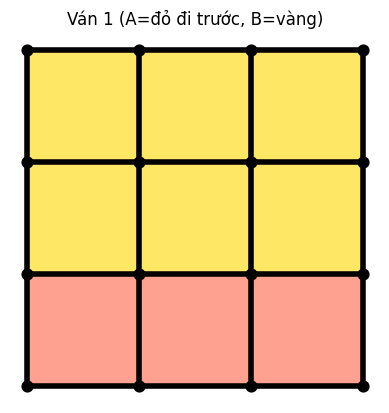

In [20]:
# Your code/ answer goes here.
# 2 tác tử heuristic khác độ sâu (không có ngẫu nhiên nên chỉ cần chơi 1 ván mỗi cách)
size = (4, 4)       # 4x4 điểm = 3x3 ô
A = make_heuristic_player(2)
B = make_heuristic_player(4)

t = time.time()
u1, fb1 = play(A, B, size=size)   # A là +1 (đi trước), B là -1
print(f"A(depth=2, đi trước) vs B(depth=4): chênh lệch ô cho A = {u1}  ({time.time()-t:.1f}s)")
u2, fb2 = play(B, A, size=size)   # B đi trước
print(f"B(depth=4, đi trước) vs A(depth=2): chênh lệch ô cho B = {u2}")
plot_board(fb1, "Ván 1 (A=đỏ đi trước, B=vàng)")

## Tournament task [+1 to 5% bonus on your course grade; will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

In [21]:
# Your code/ answer goes here.
def random_playout(board, player):
    """Chơi ngẫu nhiên đến hết ván từ thế `board` (player đang đến lượt). Trả về chênh lệch ô cho +1."""
    b = {'size': board['size'], 'lines': dict(board['lines']), 'boxes': dict(board['boxes'])}
    todo = actions(b)
    random.shuffle(todo)
    # Vì ô chỉ hoàn thành khi vẽ cạnh cuối và người vẽ cạnh đó đi tiếp, ta mô phỏng trực tiếp
    p = player
    for a in todo:
        b, p = result(b, a, p)
    return utility(b, 1)

def pure_monte_carlo_search(board, player, n_playouts=100):
    """Pure Monte Carlo Search: với mỗi nước đi, chơi n_playouts ván ngẫu nhiên rồi chọn nước có
       chênh lệch ô trung bình (theo góc nhìn của player) cao nhất. Trả về (action, bảng giá trị)."""
    values = {}
    for a in actions(board):
        nb, nxt = result(board, a, player)
        total = 0
        for _ in range(n_playouts):
            total += player * random_playout(nb, nxt)
        values[a] = total / n_playouts
    best = max(values, key=values.get)
    return best, values

def make_pmcs_player(n_playouts=100):
    def pmcs(board, player=None):
        return pure_monte_carlo_search(board, player, n_playouts)[0]
    pmcs.__name__ = f'pmcs_{n_playouts}'
    return pmcs

# 1) Thử trên 3 thế cờ đã dùng ở Task 3 (so với đáp án Alpha-Beta đầy đủ)
for name, (b, p) in {'Thế 1': (b1, p1), 'Thế 2': (b2, p2), 'Thế 3': (b3, p3)}.items():
    exact = alpha_beta_search(b, p, order=order_capture)[0]
    for n in [10, 100, 1000]:
        a, vals = pure_monte_carlo_search(b, p, n)
        print(f"{name}: N={n:<5} PMCS chọn {a} (giá trị TB {vals[a]:+.2f}) | Alpha-Beta chọn {exact} | {'TRÙNG' if a == exact else 'khác'}")

# 2) PMCS vs Random và vs Alpha-Beta trên bàn 3x3 điểm (50 ván mỗi cặp)
for N in [10, 100]:
    t = time.time()
    w, l, d = tournament(make_pmcs_player(N), random_player, n=50, size=(3, 3))
    print(f"PMCS(N={N}) vs Random      : thắng={w}, thua={l}, hòa={d}  ({time.time()-t:.1f}s)")
t = time.time()
w, l, d = tournament(make_pmcs_player(100), ab_capture, n=20, size=(3, 3))
print(f"PMCS(N=100) vs Alpha-Beta : thắng={w}, thua={l}, hòa={d}  ({time.time()-t:.1f}s)")

Thế 1: N=10    PMCS chọn ('v', 1, 0) (giá trị TB +1.60) | Alpha-Beta chọn ('h', 1, 0) | khác
Thế 1: N=100   PMCS chọn ('h', 1, 0) (giá trị TB +0.86) | Alpha-Beta chọn ('h', 1, 0) | TRÙNG
Thế 1: N=1000  PMCS chọn ('h', 2, 1) (giá trị TB +0.32) | Alpha-Beta chọn ('h', 1, 0) | khác
Thế 2: N=10    PMCS chọn ('h', 1, 0) (giá trị TB -0.80) | Alpha-Beta chọn ('h', 1, 0) | TRÙNG
Thế 2: N=100   PMCS chọn ('v', 0, 1) (giá trị TB -0.96) | Alpha-Beta chọn ('h', 1, 0) | khác
Thế 2: N=1000  PMCS chọn ('h', 1, 0) (giá trị TB -1.26) | Alpha-Beta chọn ('h', 1, 0) | TRÙNG
Thế 3: N=10    PMCS chọn ('v', 1, 0) (giá trị TB +0.80) | Alpha-Beta chọn ('v', 0, 1) | khác
Thế 3: N=100   PMCS chọn ('v', 0, 2) (giá trị TB +1.04) | Alpha-Beta chọn ('v', 0, 1) | khác
Thế 3: N=1000  PMCS chọn ('v', 0, 2) (giá trị TB +0.96) | Alpha-Beta chọn ('v', 0, 1) | khác
PMCS(N=10) vs Random      : thắng=37, thua=7, hòa=6  (2.1s)
PMCS(N=100) vs Random      : thắng=41, thua=3, hòa=6  (14.2s)
PMCS(N=100) vs Alpha-Beta : thắng=0, t

### Best First Move

How would you determine what the best first move for a standard board ($5 \times 5$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [22]:
# Your code/ answer goes here.
# Cách xác định nước đi đầu tiên tốt nhất trên bàn chuẩn 5x5 điểm (40 đoạn, 4x4 ô):
# Không thể giải chính xác -> dùng Pure Monte Carlo: với mỗi nước đi đầu, chơi N ván ngẫu nhiên và lấy
# chênh lệch ô trung bình. Dùng đối xứng của hình vuông (lật, xoay) để chỉ cần thử 1 đại diện mỗi nhóm.
def line_endpoints(l):
    o, r, c = l
    return ((r, c), (r, c + 1)) if o == 'h' else ((r, c), (r + 1, c))

def symmetry_classes(n):
    """Nhóm các đoạn thẳng của bàn n x n điểm theo 8 phép đối xứng (xoay/lật)."""
    def transforms(p):
        r, c = p; m = n - 1
        return [(r, c), (c, m - r), (m - r, m - c), (m - c, r),
                (r, m - c), (m - r, c), (c, r), (m - c, m - r)]
    classes = {}
    for l in all_lines((n, n)):
        a, b = line_endpoints(l)
        variants = [tuple(sorted((ta, tb))) for ta, tb in zip(transforms(a), transforms(b))]
        classes.setdefault(min(variants), []).append(l)
    return list(classes.values())

groups = symmetry_classes(5)
print(f"40 nước đi đầu -> {len(groups)} nhóm đối xứng, kích thước nhóm: {[len(g) for g in groups]}")

N = 10000         # số ván ngẫu nhiên cho mỗi nước đi đầu
b0 = make_board(5, 5)
rows_ = []
t = time.time()
for g in groups:
    a = g[0]
    nb, nxt = result(b0, a, 1)
    scores = [random_playout(nb, nxt) for _ in range(N)]      # chênh lệch ô cho người đi trước (+1)
    mean = sum(scores) / N
    se = (sum((x - mean) ** 2 for x in scores) / (N - 1)) ** 0.5 / N ** 0.5
    rows_.append({'nước đi (đại diện)': a, 'số nước tương đương': len(g),
                  'chênh lệch ô TB (+1 trừ -1)': round(mean, 3), 'sai số chuẩn': round(se, 3)})
print(f"Xong sau {time.time() - t:.1f}s")
df = pd.DataFrame(rows_).sort_values('chênh lệch ô TB (+1 trừ -1)', ascending=False).reset_index(drop=True)
df

40 nước đi đầu -> 6 nhóm đối xứng, kích thước nhóm: [8, 8, 8, 8, 4, 4]
Xong sau 11.6s


,nước đi (đại diện),số nước tương đương,chênh lệch ô TB (+1 trừ -1),sai số chuẩn
0,"(h, 0, 1)",8,0.074,0.087
1,"(h, 1, 1)",8,0.037,0.087
2,"(h, 1, 0)",8,0.023,0.087
3,"(h, 2, 0)",4,-0.015,0.085
4,"(h, 2, 1)",4,-0.071,0.086
5,"(h, 0, 0)",8,-0.144,0.087
